In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 160)
OUT = ROOT / "outputs"
def show(name): display(Image(filename=str(OUT / "figures" / f"{name}.png")))


# 02 Exploratory data analysis

In [2]:
pd.read_csv(OUT / 'tables' / 'descriptive_statistics.csv', index_col=0).round(3)

,count,mean,std,min,25%,50%,75%,max,skew,kurt,ann_vol
asset_id,,,,,,,,,,,
NoDur,9233.0,0.000,0.009,-0.099,-0.004,0.001,0.005,0.102,-0.192,9.498,0.148
Durbl,9233.0,0.001,0.018,-0.145,-0.008,0.001,0.009,0.189,0.048,7.050,0.292
Manuf,9233.0,0.000,0.012,-0.110,-0.005,0.001,0.006,0.107,-0.224,8.752,0.187
Enrgy,9233.0,0.001,0.016,-0.197,-0.007,0.000,0.008,0.192,-0.123,12.408,0.257
HiTec,9233.0,0.001,0.016,-0.131,-0.007,0.001,0.008,0.160,0.164,6.402,0.253
Telcm,9233.0,0.000,0.012,-0.097,-0.005,0.000,0.007,0.145,0.043,8.957,0.196
Shops,9233.0,0.001,0.012,-0.107,-0.005,0.001,0.006,0.110,-0.079,6.285,0.186
Hlth,9233.0,0.001,0.011,-0.096,-0.005,0.001,0.007,0.111,-0.171,5.334,0.181
Utils,9233.0,0.000,0.011,-0.116,-0.004,0.001,0.006,0.145,0.069,16.774,0.169


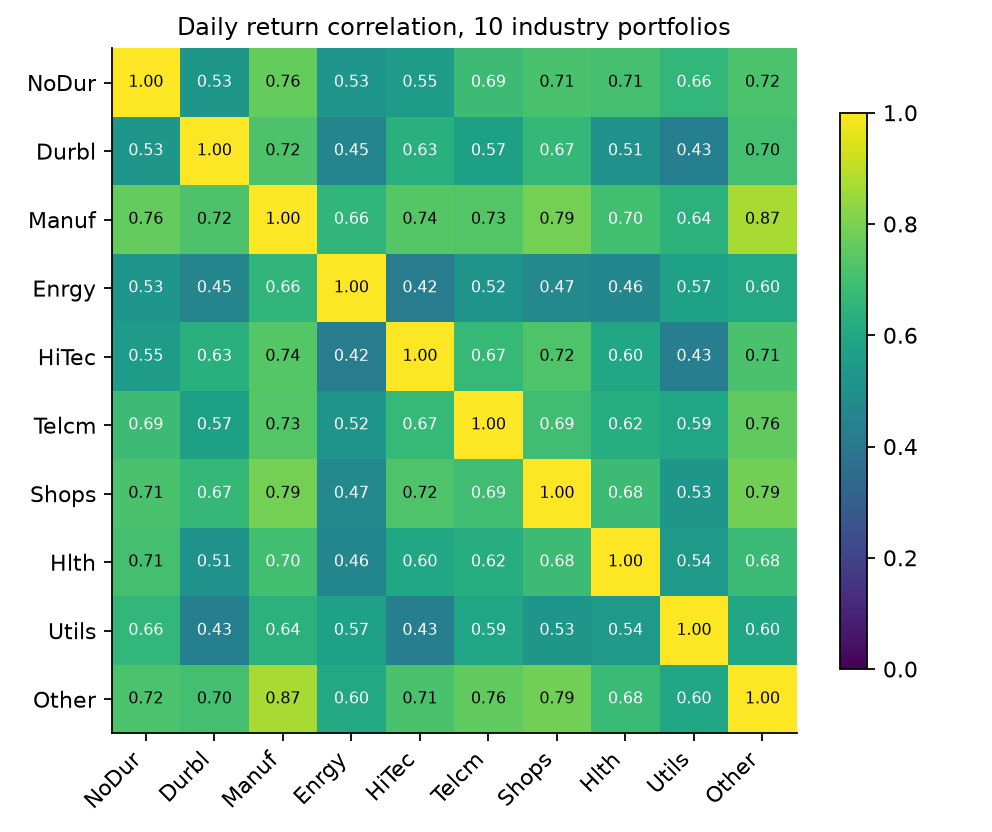

In [3]:
show('fig_correlation_heatmap')

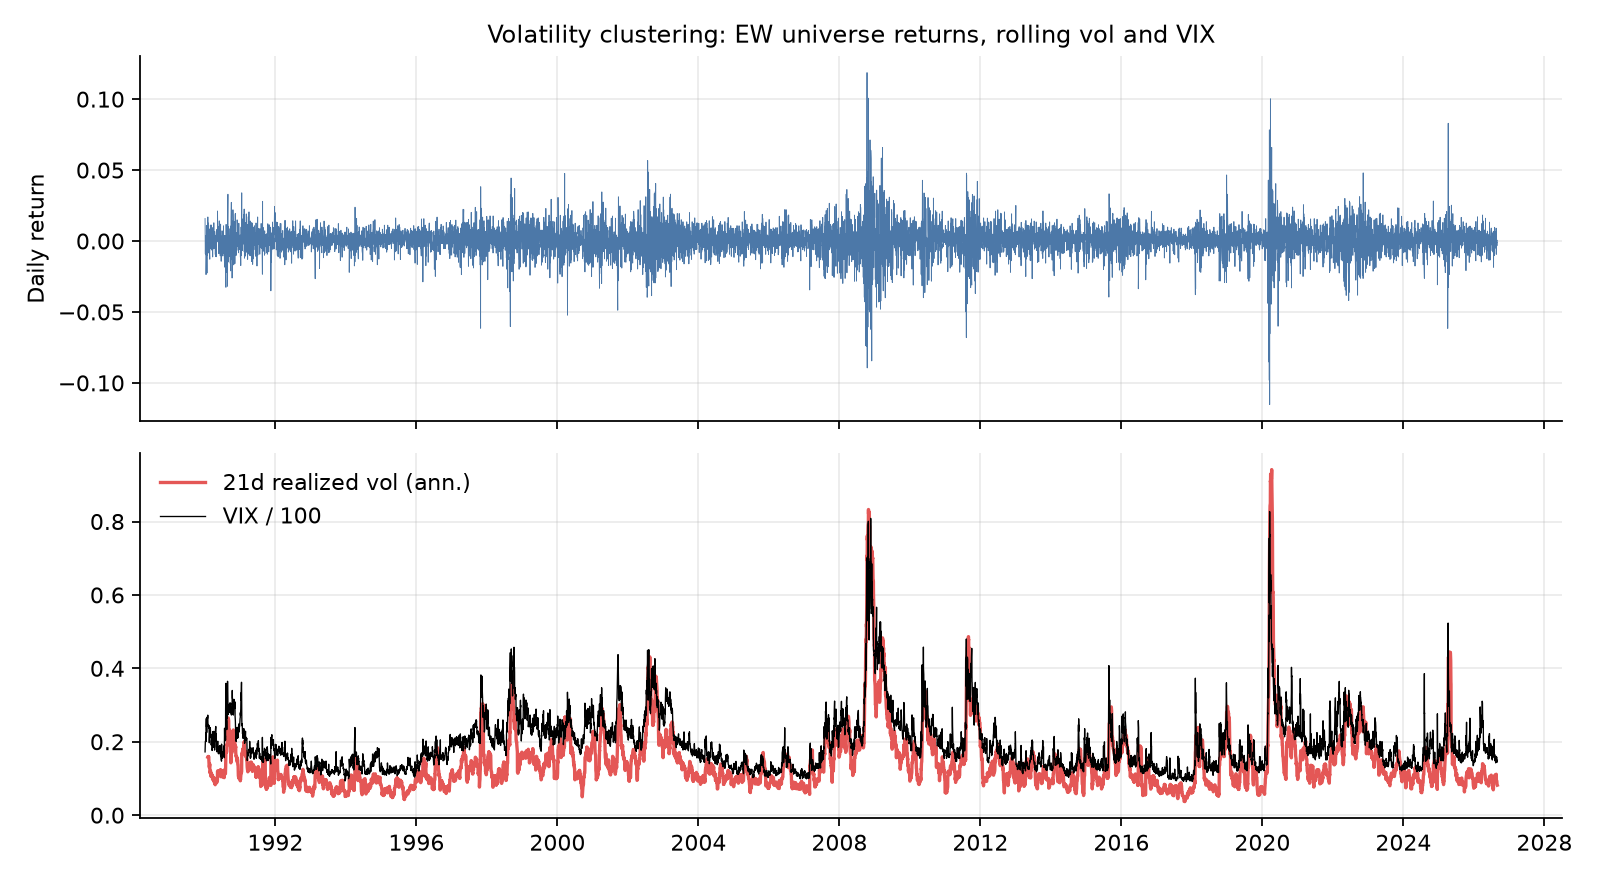

In [4]:
show('fig_volatility_clustering')

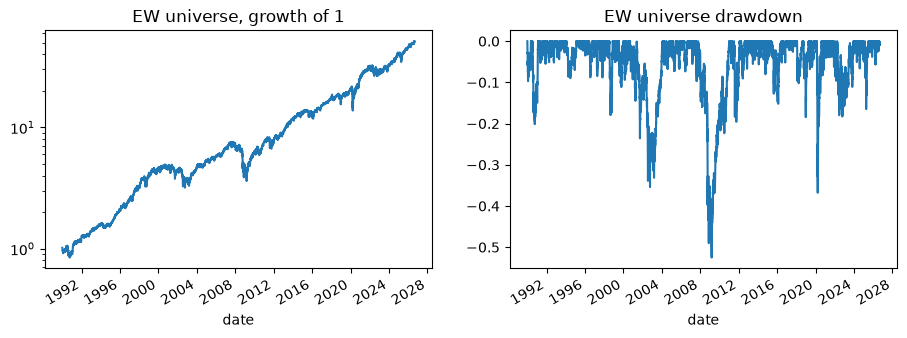

In [5]:
from src.data.align import load_processed
from src.features.returns import equal_weight_return, drawdown
from src.features.volatility import forward_realized_vol
ind, aux = load_processed()
r = equal_weight_return(ind)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
(1 + r).cumprod().plot(ax=ax[0], logy=True, title="EW universe, growth of 1")
drawdown(r).plot(ax=ax[1], title="EW universe drawdown")
plt.show()

           vix  fwd_rv5
vix      1.000    0.744
fwd_rv5  0.744    1.000


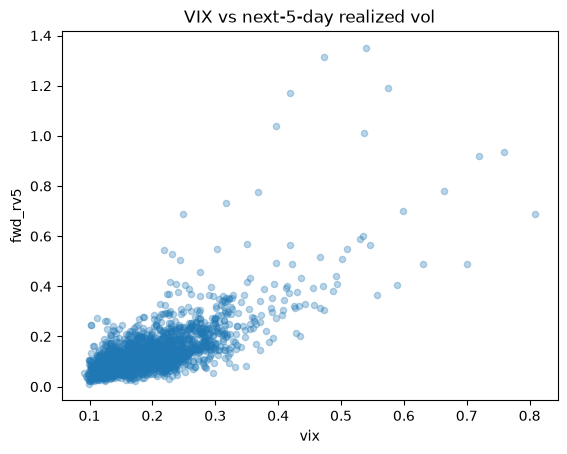

In [6]:
d = pd.DataFrame({"vix": aux["vix_close"] / 100, "fwd_rv5": forward_realized_vol(r, 5)}).dropna()
print(d.corr().round(3))
d.sample(2000, random_state=0).plot.scatter("vix", "fwd_rv5", alpha=0.3, title="VIX vs next-5-day realized vol")
plt.show()

In [7]:
flag = aux["vix_close"].shift(1) >= 25
print("stress share of days:", round(float(flag.mean()), 3))
pd.DataFrame({"stress": r[flag].describe(), "calm": r[~flag].describe()})

stress share of days: 0.173


,stress,calm
count,1601.000000,7632.000000
mean,0.000856,0.000404
std,0.019206,0.007731
min,-0.115320,-0.061500
25%,-0.009020,-0.003520
50%,0.001440,0.000780
75%,0.011370,0.004870
max,0.118700,0.047620
